# Square lattice

One orbital per site, nearest-neighbour hopping $t = -1$. At half filling the Fermi surface is perfectly nested by $M = (\pi, \pi)$ and sits on the van Hove singularity, so the bubble is largest there and a small $U$ ($U_c \approx 1.1$ at these settings) drives Néel order. Doping detunes the nesting: $U_c$ grows and $Q$ moves off $M$.

This notebook plots the output of `Square.jl`. Run that first, from the repository root, with
TRIQS available (see `examples/README.md`):
```
julia --project=. -t 4 examples/Square/Square.jl
```
The interaction file has two cases, built by `hubbard_coulomb_interactions` from the `coulomb:`
block of `Square.yml`:
- **Hubbard**: the on-site $U$ alone.
- **Coulomb**: $U$ plus a bare $1/r$ density-density tail.

The tail is pure charge (slot N, see the Conventions page of the docs). It screens the charge
channel and leaves the spin channel alone, so both cases go unstable at the same, spin-driven,
critical $U$. Their charge responses differ.

In [1]:
using Pkg
Pkg.activate(joinpath(@__DIR__, "..", ".."); io = devnull)     # the RPAToolkit checkout
using RPAToolkit, JLD2, Plots, Plots.PlotMeasures, LaTeXStrings, LinearAlgebra, Printf

default(fmt = :png, framestyle = :box, grid = false, lw = 2, size = (700, 400), dpi = 110,
        margin = 4mm, guidefontsize = 12, tickfontsize = 10, legendfontsize = 9, titlefontsize = 12)

input  = load_rpa_input(joinpath(@__DIR__, "Square.yml"))
output = load(rpa_output_path(input))
U0     = input["coulomb"]["onsite"]
entries = sort(collect(values(output)), by = e -> e["filling"])     # one per filling
half    = entries[end]                                               # n = 0.5
println(length(entries), " fillings; cases: Hubbard, Coulomb; U0 = ", U0)

5 fillings; cases: Hubbard, Coulomb; U0 = 

4.0


In [2]:
##### the channel blocks of a (4 x sites) matrix: slot N is minus charge, slots X, Y, Z are spin
spin(M)   = M[4:4:end, 4:4:end]
charge(M) = M[1:4:end, 1:4:end]
branches(M) = sort(real(eigvals(Hermitian((M + M') / 2))))
leading(M)  = last(branches(M))

##### the k-path
xs(e) = e["triqs_data"]["path_plot"]
const LABELS = [L"%$(l)" for l in input["k_labels"]]
function path_axes!(p, e)
    ticks = e["triqs_data"]["path_ticks"]
    xticks!(p, ticks, vcat(LABELS, LABELS[1:1]))
    vline!(p, ticks, color = :gray, lw = 0.8, ls = :dash, label = "")
    return p
end

##### RPA and screened interaction along the path, at strength s
scaled(e, case, s; path = true) = [s .* V for V in e[case * (path ? "_interaction_path" : "_interaction")]]
rpa_path(e, case, s)      = perform_RPA(e["combined_chis_path"], scaled(e, case, s); return_matrix = true)
screened_path(e, case, s) = effective_interaction(e["combined_chis_path"], scaled(e, case, s))

##### reciprocal lattice, the first Brillouin zone, and Q folded into it
const B = let rec = half["triqs_data"]["reciprocal"]; hcat(rec[1, 1:2], rec[2, 1:2]) end
const Gs = [B * [i, j] for i in -2:2 for j in -2:2 if (i, j) != (0, 0)]
fold(Q) = argmin(norm, [Q[1:2] .+ G for G in vcat(Gs, [[0.0, 0.0]])])
zone_edge(θ) = (u = [cos(θ), sin(θ)]; minimum(dot(G, G) / 2 / dot(u, G) for G in Gs if dot(u, G) > 1e-9))
const ZONE = [zone_edge(θ) .* [cos(θ), sin(θ)] for θ in range(0, 2π, length = 721)]

const CASES  = ("Hubbard" => (color = :royalblue, ls = :solid, marker = :circle, label = "Hubbard"),
                "Coulomb" => (color = :crimson,   ls = :dash,  marker = :diamond, label = "Hubbard + 1/r"))
filling_colors = palette(:viridis, max(length(entries), 2))
nothing

## Critical interaction

The RPA strength $s$ multiplies the whole interaction, so $U_c = s_c\,U_0$, with $U_0$ = `coulomb.onsite`.
$Q$ is the momentum of the leading eigenvalue of $\chi_\mathrm{RPA}$ just below $U_c$, in units of
the reciprocal lattice vectors.

In [3]:
println(" filling      mu     Hubbard U_c    Q (reduced)        Coulomb U_c    Q (reduced)")
for e in entries
    h, c = e["Hubbard"], e["Coulomb"]
    q(x) = "(" * join((@sprintf("%5.3f", v) for v in x["maximum reciprocal momentum"]), ", ") * ")"
    @printf("  %5.3f  %7.3f   %8.3f      %-16s   %8.3f      %s\n", e["filling"], e["mu"],
            U0 * h["critical strength"], q(h), U0 * c["critical strength"], q(c))
end

 filling      mu     Hubbard U_c    Q (reduced)        Coulomb U_c    Q (reduced)
  0.300   -1.058      3.900      (0.500, 0.312)        3.900      (0.500, 0.312)
  0.350   -0.725      3.260      (0.625, 0.500)        3.260      (0.625, 0.500)


  0.400   -0.432      2.588      (0.500, 0.417)        2.588      (0.500, 0.417)
  0.450   -0.189      1.862      (0.542, 0.500)        1.862      (0.542, 0.500)
  0.500    0.000      1.139      (0.500, 0.500)        1.139      (0.500, 0.500)


## Bands, and where each filling puts the chemical potential

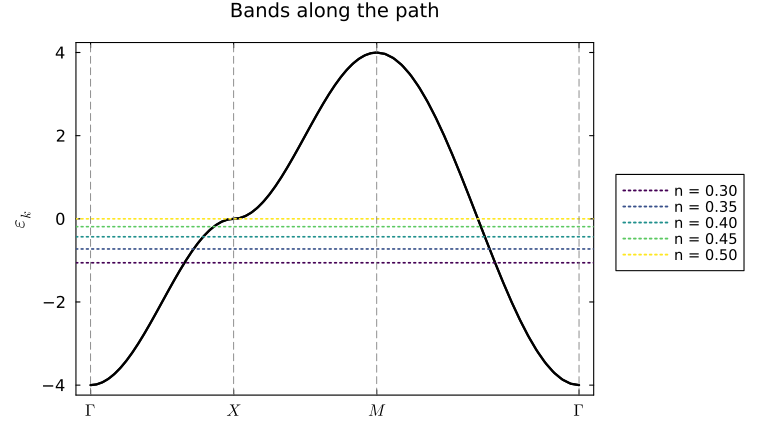

In [4]:
p = plot(title = "Bands along the path", ylabel = L"\varepsilon_k", legend = :outerright)
bands = half["triqs_data"]["bands"]
for b in axes(bands, 2)
    plot!(p, xs(half), bands[:, b], color = :black, label = "")
end
for (i, e) in enumerate(entries)
    hline!(p, [e["mu"]], color = filling_colors[i], lw = 1.5, ls = :dot, label = @sprintf("n = %.2f", e["filling"]))
end
path_axes!(p, half)

## The bare bubble

The static particle-hole bubble per spin. Without spin-orbit coupling it is the same in the charge
and all three spin channels; the interaction decides what is enhanced.

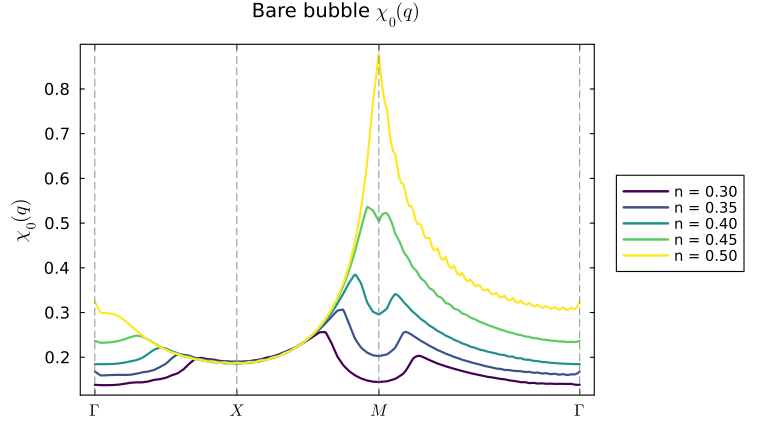

In [5]:
p = plot(title = L"Bare bubble $\chi_0(q)$", ylabel = L"\chi_0(q)", legend = :outerright)
for (i, e) in enumerate(entries)
    plot!(p, xs(e), [leading(spin(M)) for M in e["combined_chis_path"]], color = filling_colors[i],
          label = @sprintf("n = %.2f", e["filling"]))
end
path_axes!(p, half)

## RPA spin susceptibility

$\chi^s_\mathrm{RPA} = \chi_0 / (1 - U \chi_0)$, approaching the Stoner point. The divergence
grows at the ordering wavevector $Q$. Log scale.

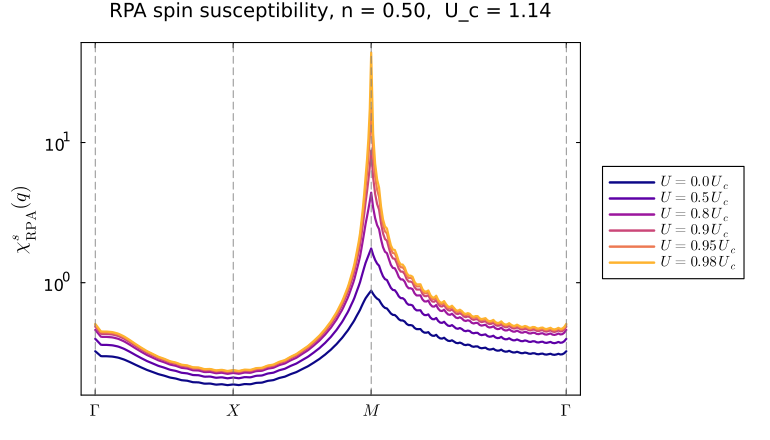

In [6]:
sc = half["Hubbard"]["critical strength"]
p  = plot(title = @sprintf("RPA spin susceptibility, n = %.2f,  U_c = %.2f", half["filling"], U0 * sc),
          ylabel = L"\chi^{s}_\mathrm{RPA}(q)", yscale = :log10, legend = :outerright)
for (j, f) in enumerate([0.0, 0.5, 0.8, 0.9, 0.95, 0.98])
    plot!(p, xs(half), [leading(spin(M)) for M in rpa_path(half, "Hubbard", f * sc)],
          color = palette(:plasma, 7)[j], label = L"U = %$(f)\,U_c")
end
path_axes!(p, half)

## RPA charge susceptibility

The same $U$ suppresses charge fluctuations, $\chi^c_\mathrm{RPA} = \chi_0 / (1 + U^c(q) \chi_0)$.
The $1/r$ tail adds $V(q)$ to $U^c$. That is largest at small $q$, so the long-wavelength charge
response is screened much more strongly.

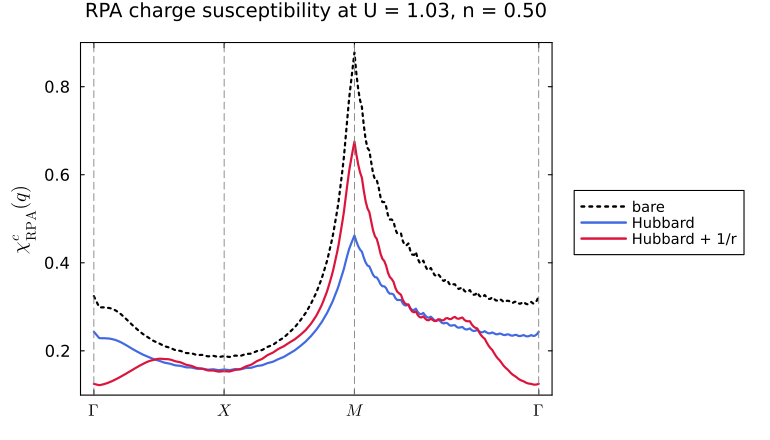

In [7]:
s = 0.9 * half["Hubbard"]["critical strength"]
p = plot(title = @sprintf("RPA charge susceptibility at U = %.2f, n = %.2f", U0 * s, half["filling"]),
         ylabel = L"\chi^{c}_\mathrm{RPA}(q)", legend = :outerright)
plot!(p, xs(half), [leading(charge(M)) for M in half["combined_chis_path"]], color = :black, ls = :dot, label = "bare")
for (case, style) in CASES
    plot!(p, xs(half), [leading(charge(M)) for M in rpa_path(half, case, s)], color = style.color, label = style.label)
end
path_axes!(p, half)

## Screened interaction

$V_\mathrm{eff} = V + V \chi_\mathrm{RPA} V$: in the spin channel $U^s/(1 - U^s \chi_0)$,
enhanced near $Q$; in the charge channel $U^c/(1 + U^c \chi_0)$, screened. Dashed lines are the
bare vertices.

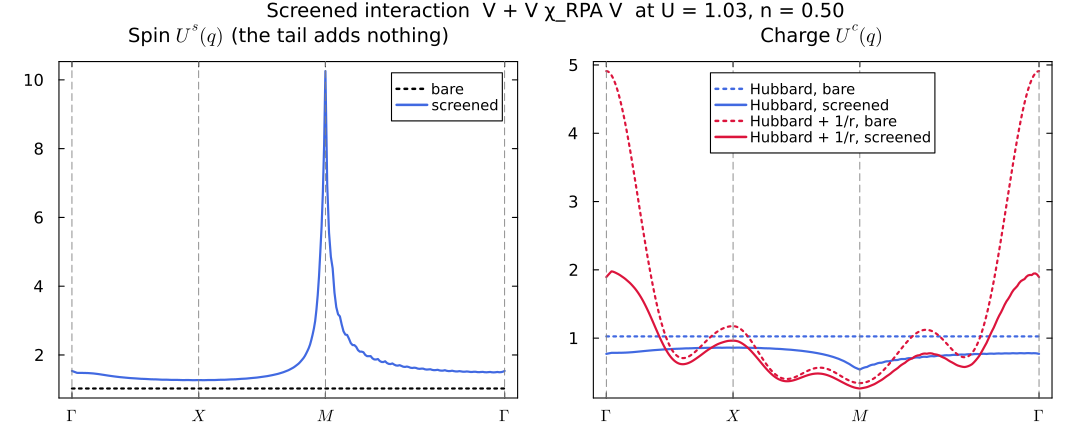

In [8]:
s  = 0.9 * half["Hubbard"]["critical strength"]
ps = plot(title = L"Spin $U^{s}(q)$ (the tail adds nothing)", legend = :topright)
plot!(ps, xs(half), [leading(spin(V)) for V in scaled(half, "Hubbard", s)], color = :black, ls = :dot, label = "bare")
plot!(ps, xs(half), [leading(spin(M)) for M in screened_path(half, "Hubbard", s)], color = :royalblue, label = "screened")
pc = plot(title = L"Charge $U^{c}(q)$", legend = :top)
for (case, style) in CASES
    plot!(pc, xs(half), [-first(branches(charge(V))) for V in scaled(half, case, s)], color = style.color, ls = :dot,
          label = "$(style.label), bare")
    plot!(pc, xs(half), [-first(branches(charge(M))) for M in screened_path(half, case, s)], color = style.color,
          label = "$(style.label), screened")
end
path_axes!(ps, half); path_axes!(pc, half)
plot(ps, pc, layout = (1, 2), size = (980, 400),
     plot_title = @sprintf("Screened interaction  V + V χ_RPA V  at U = %.2f, n = %.2f", U0 * s, half["filling"]),
     plot_titlefontsize = 12)

## Over the Brillouin zone

The leading RPA spin susceptibility at $0.9\,U_c$ on the full $k$ grid (interpolated, log
scale), with the first Brillouin zone and the ordering wavevector $Q$ that `find_instability`
reports.

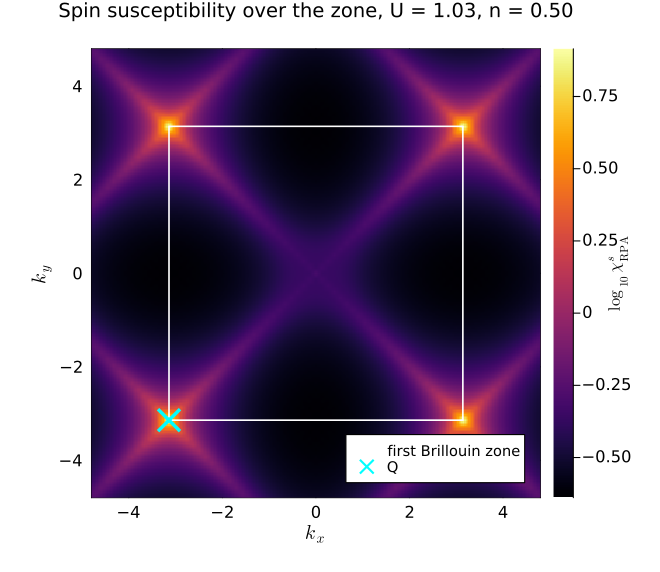

In [9]:
##### chi on the TRIQS grid k = (i b1 + j b2) / n, interpolated (periodically) onto a square of pixels
function zone_map(e, values; npix = 321)
    n = round(Int, sqrt(length(values)))
    grid = fill(NaN, n, n)
    for (row, v) in zip(eachrow(e["triqs_data"]["contracted"]), values)
        i, j = mod.(round.(Int, (B \ row[1:2]) .* n), n) .+ 1
        grid[i, j] = v
    end
    @assert !any(isnan, grid) "the bubble grid is not the n x n mesh this map assumes"
    g(i, j) = grid[mod(i, n) + 1, mod(j, n) + 1]
    function at(k)
        u = (B \ k) .* n
        i, j = floor.(Int, u); t, w = u .- (i, j)
        return (1-t)*(1-w)*g(i, j) + t*(1-w)*g(i+1, j) + (1-t)*w*g(i, j+1) + t*w*g(i+1, j+1)
    end
    box = 1.08 * maximum(norm, ZONE)
    ks  = range(-box, box, length = npix)
    return ks, [at([kx, ky]) for ky in ks, kx in ks]
end

s   = 0.9 * half["Hubbard"]["critical strength"]
chi = perform_RPA(half["combined_chis"], scaled(half, "Hubbard", s; path = false); return_matrix = true)
ks, Z = zone_map(half, [leading(spin(M)) for M in chi])
Q = fold(half["Hubbard"]["maximum momentum"])

heatmap(ks, ks, log10.(Z), aspect_ratio = 1, color = :inferno, size = (600, 520), xlims = extrema(ks), ylims = extrema(ks),
        xlabel = L"k_x", ylabel = L"k_y", colorbar_title = L"\log_{10}\,\chi^{s}_\mathrm{RPA}",
        title = @sprintf("Spin susceptibility over the zone, U = %.2f, n = %.2f", U0 * s, half["filling"]))
plot!(first.(ZONE), last.(ZONE), color = :white, lw = 1.5, label = "first Brillouin zone")
scatter!([Q[1]], [Q[2]], marker = :xcross, markersize = 10, color = :cyan, markerstrokewidth = 3, label = "Q",
         legend = :bottomright)

## Against filling

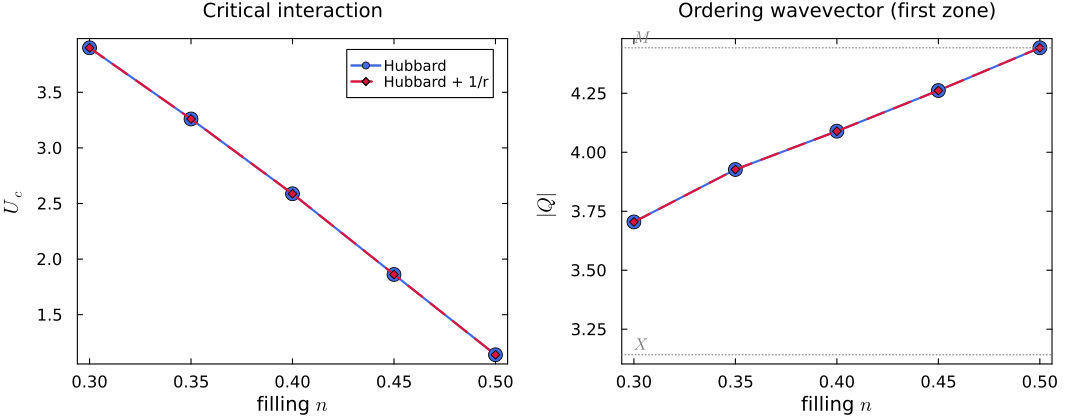

In [10]:
fill_n = [e["filling"] for e in entries]
pu = plot(ylabel = L"U_c", xlabel = L"filling $n$", title = "Critical interaction", legend = :best)
pq = plot(ylabel = L"|Q|", xlabel = L"filling $n$", title = "Ordering wavevector (first zone)", legend = false)
for (case, style) in CASES
    plot!(pu, fill_n, [U0 * e[case]["critical strength"] for e in entries], color = style.color, ls = style.ls,
          marker = style.marker, markersize = case == "Hubbard" ? 7 : 4, label = style.label)
    plot!(pq, fill_n, [norm(fold(e[case]["maximum momentum"])) for e in entries], color = style.color, ls = style.ls,
          marker = style.marker, markersize = case == "Hubbard" ? 7 : 4, label = "")
end
##### the high-symmetry points of the path, for reference
path = half["triqs_data"]["path"]; px = xs(half)
for (tick, label) in zip(half["triqs_data"]["path_ticks"][2:end-1], LABELS[2:end])
    y = norm(fold(path[argmin(abs.(px .- tick)), 1:2]))
    hline!(pq, [y], color = :gray, ls = :dot, lw = 1)
    annotate!(pq, fill_n[1], y, text(label, 10, :gray, :left, :bottom))
end
plot(pu, pq, layout = (1, 2), size = (980, 380))